Develop advanced stacking ensemble architectures combining heterogeneous models, using meta-learners to aggregate predictions, and validating the ensemble performance through nested cross-validation.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 700

In [4]:
metabolic_rate = np.random.normal(100, 15, n_samples).clip(60, 140)
plasma_concentration = np.random.exponential(scale=2.5, size=n_samples)
liver_enzyme_alt = np.random.normal(35, 12, n_samples).clip(10, 90)
kidney_gfr = np.random.normal(90, 20, n_samples).clip(30, 130)
patient_age = np.random.uniform(20, 80, n_samples)

In [5]:
toxicity_logits = (
    0.04 * (metabolic_rate - 100)
    + 0.5 * plasma_concentration
    + 0.08 * (liver_enzyme_alt - 35)
    - 0.05 * (kidney_gfr - 90)
    + 0.004 * plasma_concentration * (liver_enzyme_alt - 35) # Interaction
    - 2.5
)

In [6]:
probs = 1 / (1 + np.exp(-toxicity_logits))
target = (probs > np.median(probs)).astype(int)

In [7]:
df_stacking = pd.DataFrame({
    'metabolic_rate': metabolic_rate.round(2),
    'plasma_concentration': plasma_concentration.round(3),
    'liver_enzyme_alt': liver_enzyme_alt.round(1),
    'kidney_gfr': kidney_gfr.round(1),
    'patient_age': patient_age.round(1),
    'toxicity': target
})

In [8]:
print("Dataset Shape:", df_stacking.shape)
print("Toxicity Distribution:\n", df_stacking['toxicity'].value_counts())

Dataset Shape: (700, 6)
Toxicity Distribution:
 toxicity
1    350
0    350
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [10]:
X = df_stacking.drop(columns=['toxicity'])
y = df_stacking['toxicity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [11]:
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)),
    ('gb', HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, random_state=42)),
    ('knn', Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=9))])),
    ('svm', Pipeline([('scaler', StandardScaler()), ('svm', SVC(probability=True, C=1.0, random_state=42))]))
]

In [12]:
meta_learner = LogisticRegression(C=1.0, random_state=42)

In [14]:
stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=5,                      
    stack_method='predict_proba', 
    n_jobs=-1
)

In [15]:
stacking_clf.fit(X_train, y_train)
print("Stacking Classifier trained successfully!")

Stacking Classifier trained successfully!


In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import time

In [17]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [18]:
t0 = time.perf_counter()

In [19]:
nested_cv_scores = cross_val_score(
    stacking_clf, 
    X, 
    y, 
    cv=outer_cv, 
    scoring='f1', 
    n_jobs=-1
)
t1 = time.perf_counter()

In [21]:
print("--- Nested Cross-Validation Performance ---")
print(f"Outer 5-Fold F1 Scores : {np.round(nested_cv_scores, 4)}")
print(f"Mean Nested F1-Score   : {nested_cv_scores.mean():.4f} (+/- {nested_cv_scores.std():.4f})")
print(f"Nested CV Execution Time: {(t1 - t0):.2f} seconds")

--- Nested Cross-Validation Performance ---
Outer 5-Fold F1 Scores : [0.971  0.965  0.9379 0.9855 0.9504]
Mean Nested F1-Score   : 0.9620 (+/- 0.0165)
Nested CV Execution Time: 20.48 seconds


In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

In [23]:
standalone_results = []

for name, estimator in base_estimators:
    estimator.fit(X_train, y_train)
    y_pred = estimator.predict(X_test)
    y_proba = estimator.predict_proba(X_test)[:, 1]
    
    standalone_results.append({
        'Model': name.upper(),
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [24]:
y_pred_stack = stacking_clf.predict(X_test)
y_proba_stack = stacking_clf.predict_proba(X_test)[:, 1]

In [25]:
standalone_results.append({
    'Model': 'STACKING ENSEMBLE',
    'Accuracy': accuracy_score(y_test, y_pred_stack),
    'F1-Score': f1_score(y_test, y_pred_stack),
    'ROC-AUC': roc_auc_score(y_test, y_proba_stack)
})

In [26]:
df_results = pd.DataFrame(standalone_results).set_index('Model')
print("--- Holdout Test Performance Comparison ---")
print(df_results.round(4))

--- Holdout Test Performance Comparison ---
                   Accuracy  F1-Score  ROC-AUC
Model                                         
RF                   0.9314    0.9318   0.9910
GB                   0.9200    0.9213   0.9871
KNN                  0.9543    0.9540   0.9883
SVM                  0.9657    0.9659   0.9975
STACKING ENSEMBLE    0.9714    0.9708   0.9971


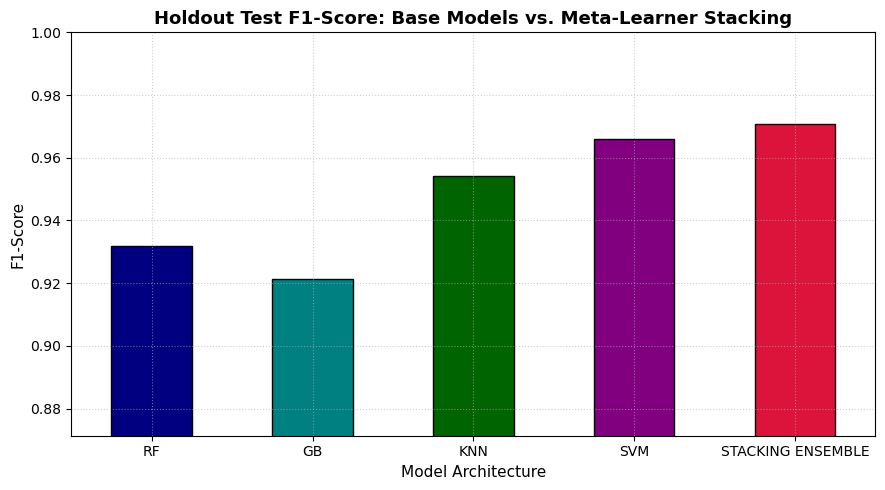

In [27]:
plt.figure(figsize=(9, 5))
df_results['F1-Score'].plot(kind='bar', color=['navy', 'teal', 'darkgreen', 'purple', 'crimson'], edgecolor='black')

plt.title("Holdout Test F1-Score: Base Models vs. Meta-Learner Stacking", fontsize=13, fontweight='bold')
plt.ylabel("F1-Score", fontsize=11)
plt.xlabel("Model Architecture", fontsize=11)
plt.ylim(df_results['F1-Score'].min() - 0.05, 1.0)
plt.xticks(rotation=0)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()